# 🏎️ 01 — Exploratory Data Analysis (EDA)

Bu notebook, **Formula 1 Data Analysis Project** kapsamında elde edilen tüm ham veri setlerini (`data/raw/`) keşfetmek için hazırlanmıştır.

## 🎯 EDA'nın Amaçları

- Verinin genel yapısını anlamak (satır, sütun, kolon tipleri)
- Eksik değerleri tespit etmek (`\N` → eksik veri işareti)
- Sayısal ve kategorik kolonların dağılımlarını incelemek
- Tutarsızlıkları, anormallikleri ve olası temizlik ihtiyaçlarını belirlemek
- 02_data_cleaning.ipynb için yapılacak dönüşümlere karar vermek

Bu aşamada **veri üzerinde değişiklik yapılmaz**, sadece analiz edilir.


## 🧰 1. Gerekli Kütüphanelerin Yüklenmesi

Aşağıdaki hücrede pandas, numpy, matplotlib ve seaborn gibi veri analizi için 
gereken temel Python kütüphaneleri içe aktarılır.

Ayrıca grafiklerin notebook içinde görüntülenmesi için ayarlar yapılır.


In [11]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid", palette="Set2")

RAW_DATA_PATH = "../data/raw/"
CSV_FILES = [...]


## 🔧 2. Yardımcı Fonksiyonların Tanımlanması

Bu bölümde, her bir veri seti için tekrar eden keşif işlemlerini otomatikleştirmek amacıyla 
`explore_dataset()` fonksiyonu yazılmıştır.

Fonksiyon; 
- veri boyutu, 
- ilk satırlar, 
- kolon tipleri, 
- eksik değerler, 
- istatistiksel özetler 
gibi bilgileri tek seferde üretir.


In [12]:
def explore_dataset(df: pd.DataFrame, name: str, show_cats=5):
    """
    Tek bir DataFrame için hızlı EDA çıktısı üretir.
    """
    print("=" * 90)
    print(f"📌 DATASET: {name}")
    print("=" * 90)
    
    print(f"\nShape: {df.shape[0]} rows, {df.shape[1]} columns")
    
    print("\nFirst 5 rows:")
    display(df.head())
    
    print("\nColumn data types:")
    print(df.dtypes)
    
    print("\nMissing values per column:")
    print(df.isna().sum())
    
    print("\nStatistical summary (numeric columns):")
    display(df.describe(include=[np.number]))
    
    print("\nStatistical summary (categorical columns):")
    display(df.describe(include=['object']))
    
    object_cols = df.select_dtypes(include=['object']).columns.tolist()
    if object_cols:
        print("\nValue counts for sample categorical columns:")
        for col in object_cols[:show_cats]:
            print(f"\nValue counts for '{col}':")
            display(df[col].value_counts().head(10))


## 📁 3. Ham Veri Setlerinin Listelenmesi

`data/raw/` klasörü içindeki tüm CSV dosyaları burada kontrol edilir.
Bu adım, notebook’un doğru klasörde çalıştığını ve tüm gerekli dosyaların mevcut olduğunu doğrular.


In [13]:
CSV_FILES = [
    "Constructor_Performance.csv",
    "Constructor_Rankings.csv",
    "Driver_Details.csv",
    "Driver_Rankings.csv",
    "Lap_Timings.csv",
    "Pit_Stop_Records.csv",
    "Qualifying_Results.csv",
    "Race_Results.csv",
    "Race_Schedule.csv",
    "Race_Status.csv",
    "Season_Summaries.csv",
    "Sprint_Race_Results.csv",
    "Team_Details.csv",
    "Track_Information.csv",
]

## 🔍 4. Tüm Ham Veri Setlerinin Keşfi

Aşağıdaki döngü, proje kapsamındaki 14 farklı CSV dosyasının tamamını:

1. Yükler  
2. `\N` → `NaN` olarak işaretler  
3. `explore_dataset()` fonksiyonu ile ayrıntılı EDA çıktıları üretir  

Bu keşifler sayesinde her bir veri setinin yapısını, eksiklerini, tutarsızlıklarını 
ve temizleme ihtiyaçlarını anlayabiliriz.


In [14]:
datasets = {}

for file in CSV_FILES:
    print(f"\n🔍 Loading {file}...")
    df = pd.read_csv(RAW_DATA_PATH + file)
    df = df.replace("\\N", np.nan)
    datasets[file] = df
    explore_dataset(df, file)



🔍 Loading Constructor_Performance.csv...
📌 DATASET: Constructor_Performance.csv

Shape: 12505 rows, 5 columns

First 5 rows:


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN



Column data types:
constructorResultsId      int64
raceId                    int64
constructorId             int64
points                  float64
status                   object
dtype: object

Missing values per column:
constructorResultsId        0
raceId                      0
constructorId               0
points                      0
status                  12488
dtype: int64

Statistical summary (numeric columns):


,constructorResultsId,raceId,constructorId,points
count,12505.000000,12505.000000,12505.000000,12505.000000
mean,8341.541783,522.379608,45.513315,3.986166
std,5629.482552,310.543824,58.912037,7.759519
min,1.000000,1.000000,1.000000,0.000000
25%,3127.000000,285.000000,6.000000,0.000000
50%,6253.000000,484.000000,22.000000,0.000000
75%,13875.000000,739.000000,53.000000,4.000000
max,17009.000000,1132.000000,215.000000,66.000000



Statistical summary (categorical columns):


...

location
California      2
Barcelona       2
Melbourne       1
Montmeló        1
Istanbul        1
Monte-Carlo     1
Montreal        1
Magny Cours     1
Silverstone     1
Kuala Lumpur    1
Name: count, dtype: int64


Value counts for 'country':


country
USA         11
France       7
Spain        6
Italy        4
Portugal     4
UK           4
Germany      3
Belgium      3
Canada       3
Japan        3
Name: count, dtype: int64


Value counts for 'url':


url
http://en.wikipedia.org/wiki/Melbourne_Grand_Prix_Circuit      1
http://en.wikipedia.org/wiki/Sepang_International_Circuit      1
http://en.wikipedia.org/wiki/Bahrain_International_Circuit     1
http://en.wikipedia.org/wiki/Circuit_de_Barcelona-Catalunya    1
http://en.wikipedia.org/wiki/Istanbul_Park                     1
http://en.wikipedia.org/wiki/Circuit_de_Monaco                 1
http://en.wikipedia.org/wiki/Circuit_Gilles_Villeneuve         1
http://en.wikipedia.org/wiki/Circuit_de_Nevers_Magny-Cours     1
http://en.wikipedia.org/wiki/Silverstone_Circuit               1
http://en.wikipedia.org/wiki/Hockenheimring                    1
Name: count, dtype: int64

## 📊 5. Ek Görselleştirmeler

Bu bölümde bazı veri setleri için hızlı görselleştirmeler yapılmıştır:

- Sürücü milliyetlerinin dağılımı  
- Sezonlara göre yarış sayısı  
- Grid pozisyonu vs bitiriş pozisyonu  

Bu grafikler, verideki temel örüntüleri anlamaya yardımcı olur.


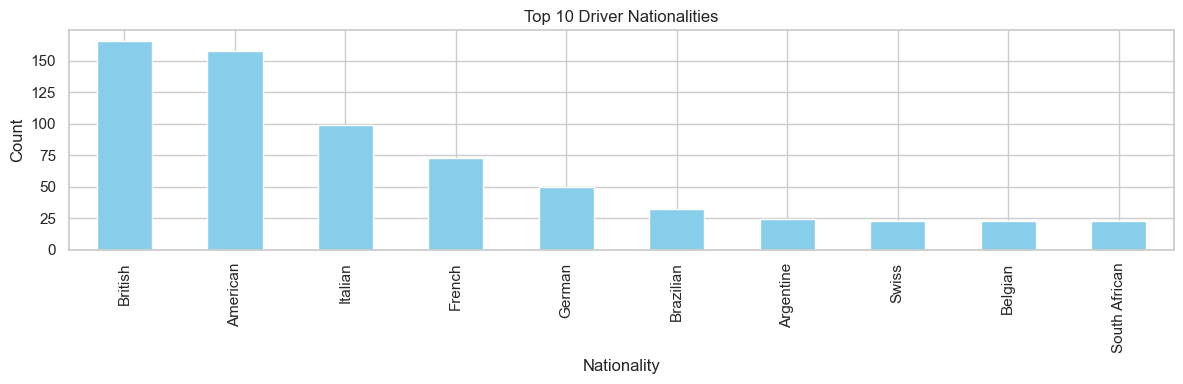

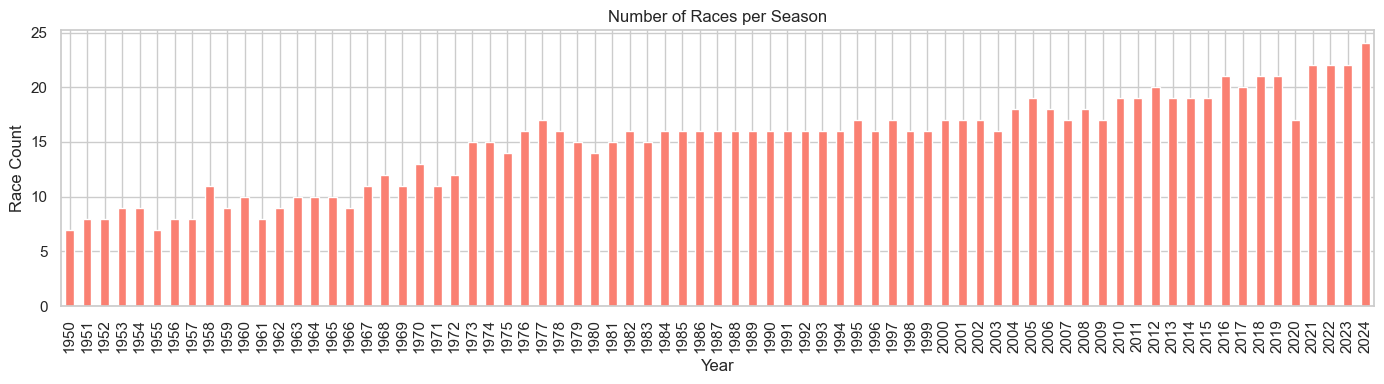

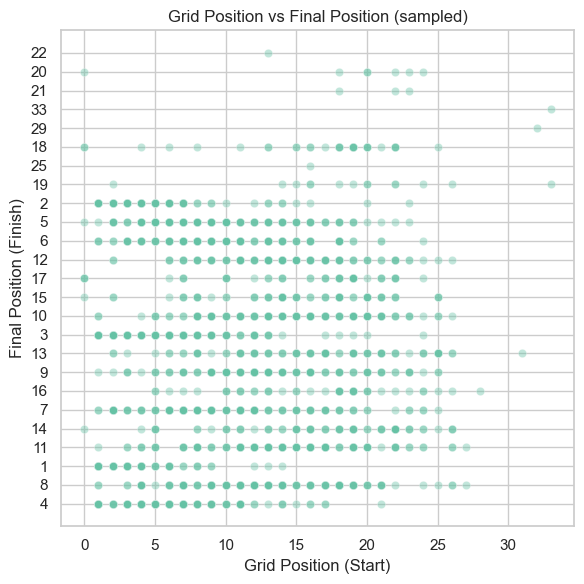

In [15]:
# 1) Driver Nationality Distribution
if "Driver_Details.csv" in datasets:
    drivers = datasets["Driver_Details.csv"]
    
    plt.figure(figsize=(12, 4))
    drivers["nationality"].value_counts().head(10).plot(kind="bar", color="skyblue")
    plt.title("Top 10 Driver Nationalities")
    plt.xlabel("Nationality")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()
else:
    print("⚠ Driver_Details.csv dataset not found in datasets dictionary.")


# 2) Number of Races per Season
if "Race_Schedule.csv" in datasets:
    schedule = datasets["Race_Schedule.csv"]
    
    plt.figure(figsize=(14, 4))
    schedule["year"].value_counts().sort_index().plot(kind="bar", color="salmon")
    plt.title("Number of Races per Season")
    plt.xlabel("Year")
    plt.ylabel("Race Count")
    plt.tight_layout()
    plt.show()
else:
    print("⚠ Race_Schedule.csv dataset not found in datasets dictionary.")


# 3) Grid Position vs Final Position Scatter Plot
if "Race_Results.csv" in datasets:
    results = datasets["Race_Results.csv"].dropna(subset=["grid", "position"])
    
    # Büyük dataset olduğu için örnek alıyoruz (performans için)
    sample = results.sample(min(2000, len(results)), random_state=42)

    plt.figure(figsize=(6, 6))
    sns.scatterplot(data=sample, x="grid", y="position", alpha=0.4)
    plt.title("Grid Position vs Final Position (sampled)")
    plt.xlabel("Grid Position (Start)")
    plt.ylabel("Final Position (Finish)")
    plt.gca().invert_yaxis()  # 1 daha iyi sonuç anlamına geldiği için
    plt.tight_layout()
    plt.show()
else:
    print("⚠ Race_Results.csv dataset not found in datasets dictionary.")


# 📚 6. EDA Sonuç Özeti

Bu notebook’ta:

- Tüm ham veri setleri tek bir yerde incelendi  
- Eksik veri (`\N`) miktarları belirlendi  
- Tarih, sayısal ve kategorik kolon tiplerindeki uyumsuzluklar gözlendi  
- Hangi kolonların temizlenmesi gerektiği tespit edildi  
- Bir sonraki aşama olan **02_data_cleaning.ipynb** için tüm gereksinimler netleşti

📌 **Sonraki Adım:**  
Ham verileri, analiz ve modelleme için daha uygun hale getirecek temizleme notebook'una geçiyoruz.
